C:\Users\lenovo\AppData\Local\Temp\ipykernel_65356\283231555.py:9: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  df = pd.read_csv('nyc_bb_bicyclist_counts.csv', header=0, infer_datetime_format=True, parse_dates=[0], index_col=[0])
C:\Users\lenovo\AppData\Local\Temp\ipykernel_65356\283231555.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv('nyc_bb_bicyclist_counts.csv', header=0, infer_datetime_format=True, parse_dates=[0], index_col=[0])


            HIGH_T  LOW_T  PRECIP  BB_COUNT  DAY_OF_WEEK
Date                                                    
2017-04-01    46.0   37.0    0.00       606            1
2017-04-02    62.1   41.0    0.00      2021            1
2017-04-03    63.0   50.0    0.03      2470            0
2017-04-04    51.1   46.0    1.18       723            0
2017-04-05    63.0   46.0    0.00      2807            0
2017-04-06    48.9   41.0    0.73       461            0
2017-04-07    48.0   43.0    0.01      1222            0
2017-04-08    55.9   39.9    0.00      1674            1
2017-04-09    66.0   45.0    0.00      2375            1
2017-04-10    73.9   55.0    0.00      3324            0
Training data set length=174
Testing data set length=40
                 Generalized Linear Model Regression Results                  
Dep. Variable:               BB_COUNT   No. Observations:                  174
Model:                            GLM   Df Residuals:                      169
Model Family:          

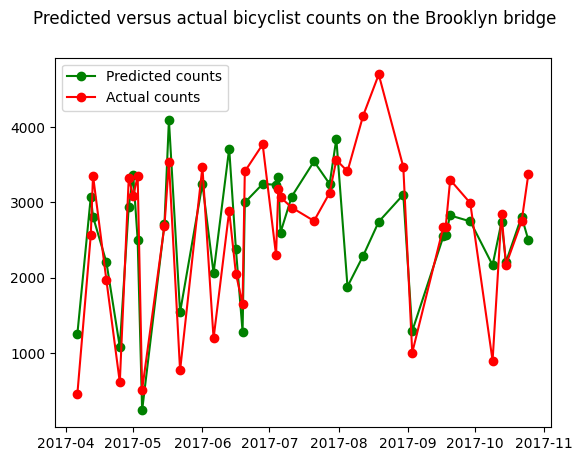

In [1]:
# Adapted from Sachin Date, The Poisson Regression Model 
import pandas as pd
from patsy import dmatrices
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

#Create a pandas DataFrame for the counts data set.
df = pd.read_csv('nyc_bb_bicyclist_counts.csv', header=0, infer_datetime_format=True, parse_dates=[0], index_col=[0])

#We'll add a few derived regression variables to the X matrix.
ds = df.index.to_series()
df['DAY_OF_WEEK'] = 1*(ds.dt.dayofweek >=5)

#Let's print out the first few rows of our data set to see how it looks like
print(df.head(10))

#Let's create the training and testing data sets.
mask = np.random.rand(len(df)) < 0.8
df_train = df[mask]
df_test = df[~mask]
print('Training data set length='+str(len(df_train)))
print('Testing data set length='+str(len(df_test)))

#Setup the regression expression in Patsy notation.
#We are telling patsy that BB_COUNT is our dependent variable y and it depends on the regression variables X:
#DAY, DAY_OF_WEEK, MONTH, HIGH_T, LOW_T and PRECIP.
expr = 'BB_COUNT ~ DAY_OF_WEEK + HIGH_T + LOW_T + PRECIP'

#Let's use Patsy to carve out the X and y matrices for the training and testing data sets:
y_train, X_train = dmatrices(expr, df_train, return_type='dataframe')
y_test, X_test = dmatrices(expr, df_test, return_type='dataframe')

#Using the statsmodels GLM class, train the Poisson regression model on the training data set.
poisson_training_results = sm.GLM(y_train, X_train, family=sm.families.Poisson(sm.genmod.families.links.Log())).fit()

#Print the training summary.
print(poisson_training_results.summary())

#Let's print out the variance and mean of the data set
print('variance='+str(df['BB_COUNT'].var()))
print('mean='+str(df['BB_COUNT'].mean()))

#Get the model's predictions on the test data set
gen_poisson_gp1_predictions = poisson_training_results.predict(X_test)

predicted_counts=gen_poisson_gp1_predictions
actual_counts = y_test['BB_COUNT']

fig = plt.figure()
fig.suptitle('Predicted versus actual bicyclist counts on the Brooklyn bridge')
predicted, = plt.plot(X_test.index, predicted_counts, 'go-', label='Predicted counts')
actual, = plt.plot(X_test.index, actual_counts, 'ro-', label='Actual counts')
plt.legend(handles=[predicted, actual])
plt.show()


In [ ]:
sm.families.family.Poisson.links

[statsmodels.genmod.families.links.Log,
 statsmodels.genmod.families.links.Identity,
 statsmodels.genmod.families.links.Sqrt]